<!-- d2l:prose id=generalization-classification-md-1 fw=all -->

# Generalization in Classification

Our Fashion-MNIST classifier achieved roughly $83\%$ accuracy on $10{,}000$ validation images. How far can we trust that number as a guarantee of performance on future garments? Two fundamental obstacles stand in the way:

1. **Finite-sample uncertainty and test-set reuse:** Even a fresh test set of $n = 10{,}000$ images is only a finite random sample, and worse still, in real development we consult the same evaluation split repeatedly as we compare models and tune hyperparameters.
2. **Memorization vs. learning:** In high dimensions where every training image is distinct, a lookup-table memorizer achieves $100\%$ training accuracy while guessing randomly on every new image. Why does a low training error for a *linear* classifier certify low population error when a memorizer's zero training error certifies nothing?

Where that section introduced overfitting and validation splits qualitatively for regression, this section makes generalization quantitative for classification: we derive exact and asymptotic confidence intervals for a test set of size $n$, quantify how selection bias and adaptive overfitting inflate scores under test-set reuse, and introduce the *Vapnik--Chervonenkis (VC) dimension* and *uniform convergence* from statistical learning theory.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=generalization-classification-md-2 fw=all -->

## The Test Set

### Empirical and Population Error

Fix a single classifier $f$ *before* drawing an independent test set $\mathcal{D} = \{(\mathbf{x}^{(i)}, y^{(i)})\}_{i=1}^n$ i.i.d. from the population distribution $P(X, Y)$. Its *empirical error* on $\mathcal{D}$ and its true *population error* are

$$\epsilon_{\mathcal{D}}(f) = \frac{1}{n}\sum_{i=1}^n \mathbf{1}\left(f(\mathbf{x}^{(i)}) \neq y^{(i)}\right), \qquad \epsilon(f) = P\left(f(X) \neq Y\right).$$

Because $f$ was fixed in advance, each error indicator $\mathbf{1}(f(\mathbf{x}^{(i)}) \neq y^{(i)})$ is an independent $\mathrm{Bernoulli}(\epsilon(f))$ coin flip with mean $\epsilon(f)$ and variance $\epsilon(f)(1 - \epsilon(f)) \leq 1/4$. Therefore, the test error $\epsilon_{\mathcal{D}}(f)$ is an unbiased estimator ($\mathbb{E}[\epsilon_{\mathcal{D}}(f)] = \epsilon(f)$) with standard error

$$\mathrm{SE}\big(\epsilon_{\mathcal{D}}(f)\big) = \sqrt{\frac{\epsilon(f)(1 - \epsilon(f))}{n}} \leq \frac{0.5}{\sqrt{n}}.$$

For our Fashion-MNIST classifier ($\epsilon(f) \approx 0.17$) on $n = 10{,}000$ test images, the standard error is $\sqrt{0.17 \times 0.83 / 10{,}000} \approx 0.0038$ ($0.38$ percentage points). Notice the $1/\sqrt{n}$ scaling law: halving our measurement uncertainty requires *four times* as many test examples.

### Confidence Intervals and Hoeffding's Inequality

To convert the standard error into a $95\%$ confidence interval $\epsilon_{\mathcal{D}}(f) \pm r$, we have two tools:

1. **Asymptotic normal interval (Central Limit Theorem):** For large $n$, $\epsilon_{\mathcal{D}}(f)$ is approximately normal, falling within $1.96$ standard errors of $\epsilon(f)$ with probability $\approx 0.95$:
   $$P\left(|\epsilon_{\mathcal{D}}(f) - \epsilon(f)| \leq 1.96\sqrt{\frac{\epsilon(f)(1 - \epsilon(f))}{n}}\right) \approx 0.95.$$
   At $\epsilon \approx 0.17$ and $n = 10{,}000$, the $95\%$ normal radius is $1.96 \times 0.0038 \approx 0.007$ ($\pm 0.7$ percentage points); in the worst case ($\epsilon = 1/2$), guaranteeing a $95\%$ radius $\leq 0.01$ takes $n \geq (1.96 \times 0.5 / 0.01)^2 = 9{,}604$ examples. This is a useful way to read the $10{,}000$-example test sets of MNIST, Fashion-MNIST, and CIFAR-10: they pin accuracy to about one point.
2. **Finite-sample Hoeffding interval:** Because the normal approximation can undercover badly when $\epsilon(f)$ is very close to $0$ (where a small test set may observe zero mistakes and collapse the plug-in normal radius to $0$), *Hoeffding's inequality* [@Hoeffding.1963] uses only the fact that each error lies in $[0, 1]$ to give an exact bound valid for every $n$ and every distribution (that section):
   $$
   P\left(|\epsilon_{\mathcal{D}}(f) - \epsilon(f)| \geq t\right) \leq 2\exp\left(-2nt^2\right).
   $$
   Setting the right-hand side to $\delta = 0.05$ yields the $95\%$ Hoeffding radius $r = \sqrt{\log(2/\delta)/(2n)}$ (requiring $n \geq \log(40)/(2 \times 0.01^2) \approx 18{,}445$ examples for $r \leq 0.01$, roughly twice the normal prescription: both assume the worst-case variance $1/4$, but Hoeffding's exponential tail bound holds for every $n$ and is looser than the exact normal quantile).

Let us simulate $10{,}000$ independent test sets across sizes $n \in [100, 10{,}000]$ for two classifiers (one with $\epsilon = 0.17$ and one with $\epsilon = 0.01$) and plot the empirical coverage of both $95\%$ intervals:

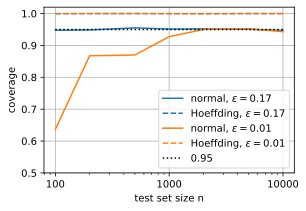

In [2]:
rng = np.random.default_rng()
num_sets = 10000
ns = np.array([100, 200, 500, 1000, 2000, 5000, 10000])
curves, legend = [], []
for eps in [0.17, 0.01]:
    # The number of errors on a test set of size n is Binomial(n, eps)
    errs = [rng.binomial(n, eps, num_sets) / n for n in ns]
    normal = [1.96 * np.sqrt(e * (1 - e) / n) for e, n in zip(errs, ns)]
    hoeffding = [np.sqrt(np.log(2 / 0.05) / (2 * n)) for n in ns]
    for name, radii in [('normal', normal), ('Hoeffding', hoeffding)]:
        curves.append([np.mean(np.abs(e - eps) <= r)  # coverage
                       for e, r in zip(errs, radii)])
        legend.append(rf'{name}, $\epsilon = {eps}$')
d2l.plot(ns, curves + [[0.95] * len(ns)], 'test set size n', 'coverage',
         legend=legend + ['0.95'], xscale='log', ylim=(0.5, 1.02),
         fmts=('C0-', 'C0--', 'C1-', 'C1--', 'k:'), figsize=(4.5, 3))

<!-- d2l:prose id=generalization-classification-md-3 fw=all -->

At $\epsilon = 0.17$, the plug-in normal interval stays close to $95\%$ coverage at every $n$; at $\epsilon = 0.01$ and small $n$, the normal interval drops to $\sim 63\%$ coverage whenever zero-error test sets occur, whereas Hoeffding's conservative interval exceeds $95\%$ coverage everywhere.

## Test Set Reuse

### Selection Among Many Classifiers

What happens when we evaluate $k$ fixed candidate classifiers $f_1, \ldots, f_k$ on the *same* test set $\mathcal{D}$ and report the winner? Even if all $k$ candidates were fixed before $\mathcal{D}$ was drawn, picking the best score cherry-picks whichever candidate got luckiest on $\mathcal{D}$. Applying the *union bound* (the probability that at least one of $k$ bad events occurs is at most the sum of their individual probabilities) to the equation gives

$$
P\left(\max_{j=1,\ldots,k} |\epsilon_{\mathcal{D}}(f_j) - \epsilon(f_j)| \geq t\right) \leq 2k\exp\left(-2nt^2\right).
$$

Setting the right-hand side to $\delta$ shows that simultaneous $1 - \delta$ accuracy across all $k$ models widens the confidence radius to $\sqrt{\log(2k/\delta)/(2n)}$. Notice the benign $\sqrt{\log k}$ growth: comparing $k = 1{,}000$ fixed models increases the radius by only a logarithmic factor, yet on $n = 1{,}000$ coin-flip test labels scored by $k = 10{,}000$ purely random coin-flipping guessers (every single one having true accuracy $0.50$), the luckiest guesser's test accuracy climbs steadily along $0.5 + \sqrt{\log(k)/(2n)}$ to $\sim 0.56$:

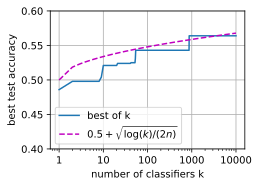

In [3]:
n, k = 1000, 10000
labels = rng.random(n) < 0.5            # one test set with coin-flip labels
guesses = rng.random((k, n)) < 0.5      # k classifiers that guess at random
accuracy = (guesses == labels).mean(axis=1)
ks = np.arange(1, k + 1)
d2l.plot(ks, [np.maximum.accumulate(accuracy),
              0.5 + np.sqrt(np.log(ks) / (2 * n))],
         'number of classifiers k', 'best test accuracy',
         legend=['best of k', r'$0.5 + \sqrt{\log(k) / (2n)}$'], xscale='log',
         ylim=(0.4, 0.6))

<!-- d2l:prose id=generalization-classification-md-4 fw=all -->

### Adaptive Overfitting

Selection bias grows far more dangerous when new candidates are chosen *adaptively* based on previous test scores [@Dwork.Feldman.Hardt.ea.2015]. Once test feedback guides model design, the classifiers are no longer independent of $\mathcal{D}$ and the union bound the equation breaks down completely. Following @Blum.Hardt.2015, watch what happens if we take just the first $1{,}000$ random coin-flipping guessers above, select only those that happened to score above $0.50$ on the test set, and take their majority vote on each test example:

In [4]:
kept = guesses[:1000][accuracy[:1000] > 0.5]  # guessers that scored above 0.5
vote = kept.mean(axis=0) > 0.5                # their majority vote
print(f'majority vote: {(vote == labels).mean():.3f}, '
      f'best single guesser: {accuracy[:1000].max():.3f}')

majority vote: 0.709, best single guesser: 0.564


<!-- d2l:prose id=generalization-classification-md-5 fw=all -->

Without ever seeing an individual test label, using only $1{,}000$ scalar accuracy queries, the majority vote of pure coin flippers jumps to $\sim 70\%$ test accuracy while still having $50\%$ population accuracy on any new data. (In fact, $O(n)$ queries can reconstruct every test label; see Exercise 3.) This is why hyperparameter tuning and architecture exploration belong on a validation split (Exercise 4), leaving the test set for one-shot final evaluation.

How much damage has a decade of reuse done to the standard benchmarks? When @Recht.Roelofs.Schmidt.ea.2019 collected fresh test sets for CIFAR-10 and ImageNet, accuracies fell by $3$ to $15$ points, yet the ranking of the models barely changed. The worst case above is possible, but ordinary model development had overfit these test sets far less than the theory permits. The drop itself is better explained by a small change in the data distribution, which is the subject of that section.

## Statistical Learning Theory

### Uniform Convergence

How can we guarantee *a priori* that a classifier $f_{\mathcal{S}}$ selected from a hypothesis class $\mathcal{F}$ by minimizing training error $\epsilon_{\mathcal{S}}(f)$ on a training set $\mathcal{S}$ of size $n$ will generalize to the population? Since the learner picks $f_{\mathcal{S}} \in \mathcal{F}$ after inspecting $\mathcal{S}$, we need the training error to stay close to the population error *simultaneously for every $f \in \mathcal{F}$* (*uniform convergence*). If $\mathcal{F}$ is finite ($|\mathcal{F}| < \infty$), applying the union bound the equation across all $k = |\mathcal{F}|$ hypotheses on $\mathcal{S}$ yields, with probability at least $1 - \delta$,

$$
|\epsilon_{\mathcal{S}}(f) - \epsilon(f)| \leq \sqrt{\frac{\log(2|\mathcal{F}|/\delta)}{2n}} \quad \textrm{for every } f \in \mathcal{F}.
$$

### The VC Dimension and the VC Bound

For continuous parameter families like linear halfspaces $f(\mathbf{x}) = \operatorname{sign}(\mathbf{w}^\top\mathbf{x} + b)$ on $\mathbb{R}^d$, $|\mathcal{F}| = \infty$, making the equation vacuous. Yet @Vapnik.Chervonenkis.1971 observed that on any finite set of $n$ points, two classifiers that produce the exact same binary $\pm 1$ labeling are indistinguishable on $\mathcal{S}$. We say that $\mathcal{F}$ *shatters* a set of $m$ points if functions in $\mathcal{F}$ can realize all $2^m$ possible binary labelings of those $m$ points. The *Vapnik--Chervonenkis (VC) dimension* $v = \mathrm{VC}(\mathcal{F})$ is the size of the largest set of points that $\mathcal{F}$ can shatter:

- **Lines in the plane ($\mathbb{R}^2$) have VC dimension $3$ (the figure):** Any three non-collinear points can be shattered in all $2^3 = 8$ ways by a straight line, whereas no four points in $\mathbb{R}^2$ can ever be shattered (splitting opposite corners of a convex quadrilateral requires crossing diagonals, and a halfplane containing the three vertices of a triangle automatically contains any point inside it).
- **Linear halfspaces in $\mathbb{R}^d$ have VC dimension $d + 1$ (Exercise 5):** They shatter the origin and the $d$ standard basis vectors, and by Radon's theorem no $d + 2$ points in $\mathbb{R}^d$ can be shattered.
- **Unconstrained lookup-table memorizers have $v = \infty$:** They shatter every finite set of distinct points.

![Lines in $\mathbb{R}^2$ shatter three non-collinear points (left, all $2^3 = 8$ labelings) but cannot shatter any four points (middle and right).](../img/mdl-clf-shattering.svg)

By *Sauer's lemma*, once $n \geq v$, the number of distinct labelings that a class of VC dimension $v$ can induce on $n$ points grows only polynomially—at most $(en/v)^v$ rather than $2^n$. Running a symmetrized union bound over those labelings (that section) yields the *VC bound*: for an absolute constant $c$, with probability at least $1 - \delta$ over the training draw $\mathcal{S}$,

$$
\epsilon(f) \leq \epsilon_{\mathcal{S}}(f) + c\sqrt{\frac{v + \log(1/\delta)}{n}} \quad \textrm{for every } f \in \mathcal{F}.
$$

This theorem answers our conceptual puzzle: because linear classifiers in $\mathbb{R}^d$ have finite VC dimension $v = d + 1$, driving training error low when $n \gg d$ guarantees low population error for *any* distribution $P$, whereas an infinite-VC memorizer enjoys no bound at all. At the same time, because worst-case uniform convergence bounds must hold even for adversarial distributions, the equation is numerically loose on natural images (for a single one-vs-rest halfspace $\sqrt{785 / 60{,}000} \approx 0.11$ before the constant $c$, and the capacity of all ten classes together is larger still, versus our empirical $0.01$ train--test gap on Fashion-MNIST) and becomes vacuous ($v \geq n$) for overparameterized deep neural networks capable of memorizing random labels [@zhang2021understanding]. We return to that puzzle in that section while relying on held-out test sets for sharp empirical measurement.

## Summary

On an untouched test set of $n$ examples, a fixed classifier's empirical error $\epsilon_{\mathcal{D}}(f)$ has standard error $\sqrt{\epsilon(1-\epsilon)/n} \leq 0.5/\sqrt{n}$, so pinning accuracy to within one percentage point at $95\%$ confidence requires roughly $10{,}000$ test examples under the normal approximation or $18{,}500$ under Hoeffding's finite-sample bound. Reusing the same test set to select among $k$ fixed models widens that uncertainty slowly as $\sqrt{\log(2k/\delta)/(2n)}$, whereas adaptive design guided by past test scores can overfit a test set in far fewer queries. To bound generalization from training error alone, statistical learning theory measures hypothesis-class capacity by the VC dimension $v$—the largest set of points the class can shatter ($v = d + 1$ for linear halfspaces in $\mathbb{R}^d$)—yielding a uniform $O(\sqrt{v/n})$ bound that explains why linear models cannot memorize large datasets while remaining vacuous for overparameterized deep networks.

## Exercises

1. **Two models, one test set.** A paper reports that model A reaches
   91.2% and model B 91.6% on a test set of 10,000 images.
    1. Compute the standard error of each accuracy and the 95% radius of
       the normal approximation. Is the difference of 0.4 points
       meaningful if the two models were evaluated on two independent test
       sets of this size?
    1. Both models were in fact evaluated on the same 10,000 images.
       Explain why the question is now about the images on which the two
       models disagree, and describe how you would decide it if the paper
       reported, for every test image, which models got it right.
    1. How large a test set would make a 0.4-point difference between two
       independently evaluated models lie outside the radius?


1. **No errors on the test set.** A classifier makes no error on a test
   set of $n$ examples.
    1. State the interval that the normal approximation, with
       $\epsilon_{\mathcal{D}}(f)$ in place of $\epsilon(f)$, reports, and
       the Hoeffding interval.
    1. Show that a classifier with population error $\epsilon$ makes no
       error on $n$ independent test examples with probability
       $(1 - \epsilon)^n \leq e^{-n\epsilon}$. Conclude that if
       $\epsilon \geq 3/n$, a test set without errors occurs with
       probability below 0.05 (the "rule of three").
    1. Compare $3/n$ with the Hoeffding radius for $n = 100$ and
       $n = 10{,}000$, and explain the difference.

1. **Leaking a test set.** Somebody else holds a test set $\mathcal{D}$ of
   $n$ examples with binary labels and releases only the inputs. You may
   submit any model $f$, with no restriction on the model class, and you
   receive only its test error $\epsilon_{\mathcal{D}}(f)$.
    1. Give a strategy that recovers every test label, and hence a model
       with test error $0$ whatever its population error, and count the
       submissions it uses.
    1. Each answer $\epsilon_{\mathcal{D}}(f)$ takes one of $n+1$ values.
       Use this to lower-bound the number of submissions that any
       strategy needs to distinguish all $2^n$ labelings.

1. [code] **A validation split for Fashion-MNIST.** The chapter selected
   models on the 10,000 test images. Hold out 10,000 of the 60,000 training
   images as a validation split instead, and train softmax regression on
   the remaining 50,000.
    1. Choose the learning rate from $\{0.01, 0.03, 0.1, 0.3, 1\}$ by its
       accuracy on the validation split.
    1. Evaluate the selected model once on the test images, and compare its
       test accuracy with its validation accuracy. Is the difference within
       the radius of the 95% interval for 10,000 examples?
    1. Explain why the test accuracy, measured once after the choice, is an
       unbiased estimate for the selected model, while the best validation
       accuracy is not.

1. **VC dimension of linear classifiers.** ● Consider the linear classifiers
   $f(\mathbf{x}) = \operatorname{sign}(\mathbf{w}^\top \mathbf{x} + b)$ on
   $\mathbb{R}^d$.
    1. Show that they shatter the $d+1$ points
       $\mathbf{0}, \mathbf{e}_1, \ldots, \mathbf{e}_d$. Given arbitrary
       labels $y_0, y_1, \ldots, y_d \in \{\pm 1\}$, construct $b$ and
       $\mathbf{w}$ that produce them. Hint: $f(\mathbf{0})$ depends on $b$
       alone, so choose $b$ first.
    1. Let $\mathbf{x}_1, \ldots, \mathbf{x}_{d+2} \in \mathbb{R}^d$. Show
       that the $d + 2$ vectors $[\mathbf{x}_i, 1] \in \mathbb{R}^{d+1}$,
       each $\mathbf{x}_i$ with a 1 appended, are linearly dependent, so that
       $\sum_i a_i [\mathbf{x}_i, 1] = \mathbf{0}$ for some $a_i$ that are
       not all zero. Let $I$ be the indices with
       $a_i > 0$ and $J$ those with $a_i < 0$. Show that neither is empty and
       that no linear classifier labels the points in $I$ with $+1$ and those
       in $J$ with $-1$. Hint: evaluate
       $\sum_i a_i (\mathbf{w}^\top \mathbf{x}_i + b)$ in two ways.
    1. Conclude that the VC dimension is $d + 1$, and show that the convex
       hulls of $\{\mathbf{x}_i : i \in I\}$ and
       $\{\mathbf{x}_j : j \in J\}$ intersect.


1. **VC dimension of polynomials.** What is the VC dimension of the class
   of classifiers $f(x) = \operatorname{sign}(p(x))$ with $p$ a polynomial
   of degree at most five in $x \in \mathbb{R}$? What is it for
   $\mathbf{x} \in \mathbb{R}^d$? Hint: such a classifier is a linear
   classifier on the monomials of $\mathbf{x}$. Then say what the VC
   bound predicts for the training error of a degree-five polynomial
   classifier on Fashion-MNIST, and why nobody trains one.

[Discussions](https://d2l.discourse.group/t/6829)